In [1]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils
# noinspection PyUnresolvedReferences
from utils import artificializer

# noinspection PyUnresolvedReferences
from models import bom
# noinspection PyUnresolvedReferences
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/worm-2025-fieseler/import/models/hgm.py'>

# Functions

In [3]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

In [4]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

# read & prep

In [5]:
selection_n_scores = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',		# paper
					  'RMDDR', 'SMDDR', 'SMDDL',					# C
					  'AVAR', 'AVAL',								# M
					  'ALA', 'AWBR', 'AWBR']						# O
selection_n_traces = ['DB01', 'VB02', 'DD01', 'AVAR', 'ALA']

selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']


dims = 2  # just for the comparison cca


# read_ids = list(range(0, 33+1))
# read_ids = [0, 12, 14, 23, 29, 32]
read_ids = [14]
plot_id = 14


gfp = True
if gfp:
	# read_ids_gfp = list(range(0, 7+1))
	read_ids_gfp = [0]
	plot_id_gfp = 0

# artificial = True

In [6]:
# read
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_data(path, read_ids)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# remove unused discrete state labels
discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])


if gfp:
	# read
	path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
	(file_ids_gfp, filenames_gfp,
	 traces_gfp,
	 continuous_behaviors_gfp,
	 discrete_states_gfp, eigenworms_gfp,
	 kymographs_gfp) = read_utils.get_data(path_gfp, read_ids_gfp)

	# clear nan values
	for i in range(len(file_ids_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)

		traces_gfp[i] = traces_gfp[i][mask]
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	# remove unused discrete state labels
	discrete_states_gfp = [ds[selection_bhl] for ds in discrete_states_gfp]

	# naive ID unknown neurons
	for i in range(len(file_ids_gfp)):
		traces_gfp[i].columns = pd.Index([
			f'{file_ids_gfp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gfp[i].columns, traces_gfp[i].columns == ''))
		])

# read models

In [7]:
w1 = 1E-3	# 1E-4
w2 = 1E-5	# 1E-4

bom_load_name_gcamp = f'bom_gcamp_w1-{w1:.0E}_w2-{w2:.0E}'
hgm_load_name_gcamp = f'hgm_gcamp_w1-{w1:.0E}_w2-{w2:.0E}'

if gfp:
	bom_load_name_gfp = f'bom_gfp_w1-{w1:.0E}_w2-{w2:.0E}'
	hgm_load_name_gfp = f'hgm_gfp_w1-{w1:.0E}_w2-{w2:.0E}'

In [8]:
boms_params_gcamp = train_utils.load_params(bom_load_name_gcamp, filenames_gcamp)

boms_losses_gcamp_all = train_utils.load_losses(bom_load_name_gcamp, filenames_gcamp)
boms_losses_gcamp = [losses[0] for losses in boms_losses_gcamp_all]
boms_man_losses_gcamp = [losses[1] for losses in boms_losses_gcamp_all]
boms_res_losses_gcamp = [losses[2] for losses in boms_losses_gcamp_all]
boms_mpe_losses_gcamp = [losses[3] for losses in boms_losses_gcamp_all]
boms_losses_train_gcamp = [losses[4] for losses in boms_losses_gcamp_all]
boms_man_losses_train_gcamp = [losses[5] for losses in boms_losses_gcamp_all]
boms_res_losses_train_gcamp = [losses[6] for losses in boms_losses_gcamp_all]
boms_mpe_losses_train_gcamp = [losses[7] for losses in boms_losses_gcamp_all]

hgms_params_gcamp = train_utils.load_params(hgm_load_name_gcamp, filenames_gcamp)

hgms_losses_gcamp_all = train_utils.load_losses(hgm_load_name_gcamp, filenames_gcamp)
hgms_losses_gcamp = [losses[0] for losses in hgms_losses_gcamp_all]
hgms_man_losses_gcamp = [losses[1] for losses in hgms_losses_gcamp_all]
hgms_res_losses_gcamp = [losses[2] for losses in hgms_losses_gcamp_all]
hgms_mpe_losses_gcamp = [losses[3] for losses in hgms_losses_gcamp_all]
hgms_losses_train_gcamp = [losses[4] for losses in hgms_losses_gcamp_all]
hgms_man_losses_train_gcamp = [losses[5] for losses in hgms_losses_gcamp_all]
hgms_res_losses_train_gcamp = [losses[6] for losses in hgms_losses_gcamp_all]
hgms_mpe_losses_train_gcamp = [losses[7] for losses in hgms_losses_gcamp_all]


if gfp:
	boms_params_gfp = train_utils.load_params(bom_load_name_gfp, filenames_gfp)

	boms_losses_gfp_all = train_utils.load_losses(bom_load_name_gfp, filenames_gfp)
	boms_losses_gfp = [losses[0] for losses in boms_losses_gfp_all]
	boms_man_losses_gfp = [losses[1] for losses in boms_losses_gfp_all]
	boms_res_losses_gfp = [losses[2] for losses in boms_losses_gfp_all]
	boms_mpe_losses_gfp = [losses[3] for losses in boms_losses_gfp_all]
	boms_losses_train_gfp = [losses[4] for losses in boms_losses_gfp_all]
	boms_man_losses_train_gfp = [losses[5] for losses in boms_losses_gfp_all]
	boms_res_losses_train_gfp = [losses[6] for losses in boms_losses_gfp_all]
	boms_mpe_losses_train_gfp = [losses[7] for losses in boms_losses_gfp_all]

	hgms_params_gfp = train_utils.load_params(hgm_load_name_gfp, filenames_gfp)

	hgms_losses_gfp_all = train_utils.load_losses(hgm_load_name_gfp, filenames_gfp)
	hgms_losses_gfp = [losses[0] for losses in hgms_losses_gfp_all]
	hgms_man_losses_gfp = [losses[1] for losses in hgms_losses_gfp_all]
	hgms_res_losses_gfp = [losses[2] for losses in hgms_losses_gfp_all]
	hgms_mpe_losses_gfp = [losses[3] for losses in hgms_losses_gfp_all]
	hgms_losses_train_gfp = [losses[4] for losses in hgms_losses_gfp_all]
	hgms_man_losses_train_gfp = [losses[5] for losses in hgms_losses_gfp_all]
	hgms_res_losses_train_gfp = [losses[6] for losses in hgms_losses_gfp_all]
	hgms_mpe_losses_train_gfp = [losses[7] for losses in hgms_losses_gfp_all]

## predict & score gcamp

In [9]:
splits_gcamp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gcamp[i].shape[0]), discrete_states_gcamp[i]['REV'].values)) for i in range(len(file_ids_gcamp))]

In [10]:
boms_spn_man_rec_res_pres_gcamp = [[
	bom.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(boms_params_gcamp[i], splits_gcamp[i])
] for i in range(len(file_ids_gcamp))]

hgms_spn_man_rec_res_pres_gcamp = [[
	hgm.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(hgms_params_gcamp[i], splits_gcamp[i])
] for i in range(len(file_ids_gcamp))]

In [11]:
boms_spn_gcamp = [
	[
		pd.DataFrame(data=np.array(split[0])[None], columns=traces_gcamp[i].columns) for split in boms_spn_man_rec_res_pres_gcamp[i]
	] for i in range(len(file_ids_gcamp))
]
boms_man_gcamp = [
	[
		pd.DataFrame(data=np.array(split[1]), columns=[f'M{i}' for i in range(dims)]) for split in boms_spn_man_rec_res_pres_gcamp[i]
	] for i in range(len(file_ids_gcamp))
]
(boms_rec_gcamp,
 boms_res_gcamp,
 boms_pres_gcamp) = tuple(
	[
		[
			pd.DataFrame(data=np.array(split[m]), columns=traces_gcamp[i].columns) for split in boms_spn_man_rec_res_pres_gcamp[i]
		] for i in range(len(file_ids_gcamp))
	] for m in [2, 3, 4]
)


hgms_spn_gcamp = [
	[
		pd.DataFrame(data=np.array(split[0])[None], columns=traces_gcamp[i].columns) for split in hgms_spn_man_rec_res_pres_gcamp[i]
	] for i in range(len(file_ids_gcamp))
]
hgms_man_gcamp = [
	[
		pd.DataFrame(data=np.array(split[1]), columns=[f'M{i}' for i in range(dims)]) for split in hgms_spn_man_rec_res_pres_gcamp[i]
	] for i in range(len(file_ids_gcamp))
]
(hgms_rec_gcamp,
 hgms_res_gcamp,
 hgms_pres_gcamp) = tuple(
	[
		[
			pd.DataFrame(data=np.array(split[m]), columns=traces_gcamp[i].columns) for split in hgms_spn_man_rec_res_pres_gcamp[i]
		] for i in range(len(file_ids_gcamp))
	] for m in [2, 3, 4]
)

## losses

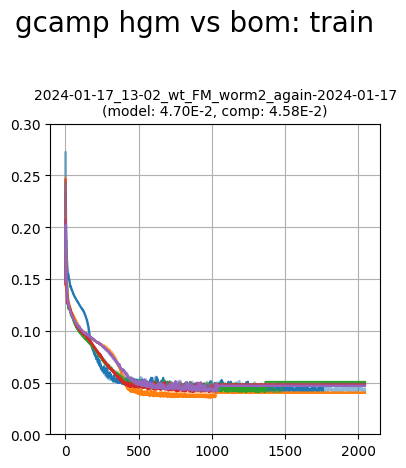

In [12]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: train',
							  filenames_gcamp,
							  hgms_losses_train_gcamp, boms_losses_train_gcamp,
							  ylimits=None)

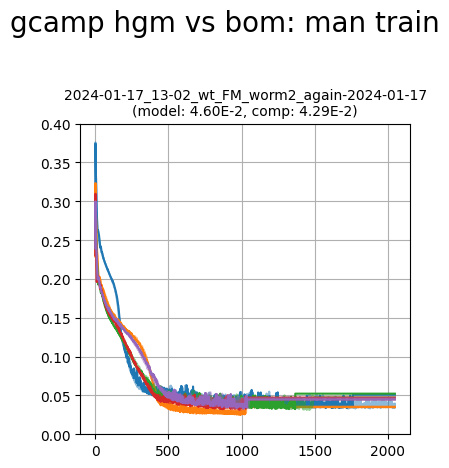

In [13]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: man train',
							  filenames_gcamp,
							  hgms_man_losses_train_gcamp, boms_man_losses_train_gcamp,
							  ylimits=None)

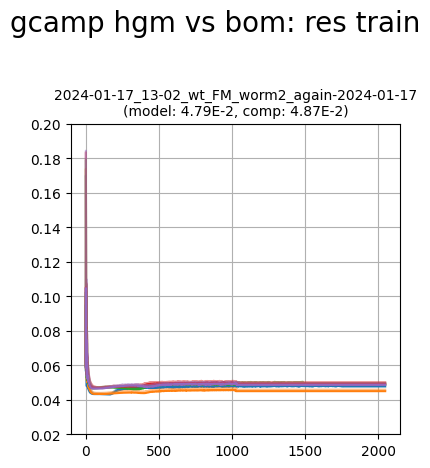

In [14]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: res train',
							  filenames_gcamp,
							  hgms_res_losses_train_gcamp, boms_res_losses_train_gcamp,
							  ylimits=None)

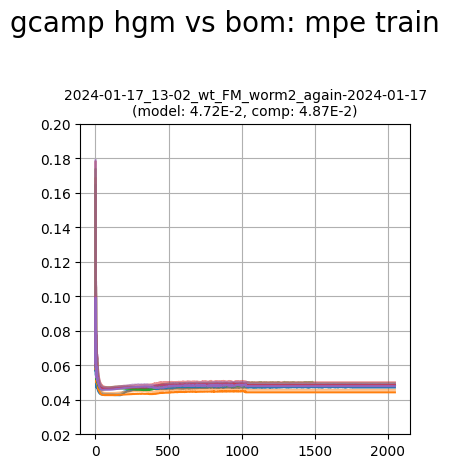

In [15]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe train',
							  filenames_gcamp,
							  hgms_mpe_losses_train_gcamp, boms_mpe_losses_train_gcamp,
							  ylimits=None)

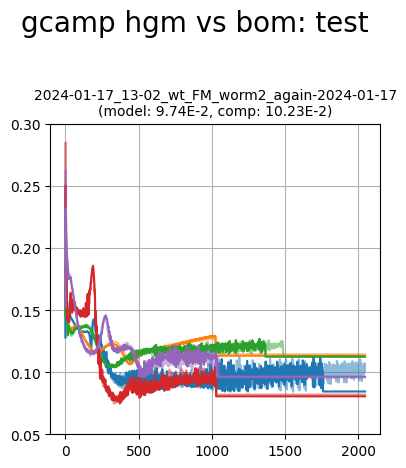

In [16]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: test',
							  filenames_gcamp,
							  hgms_losses_gcamp, boms_losses_gcamp,
							  ylimits=None)

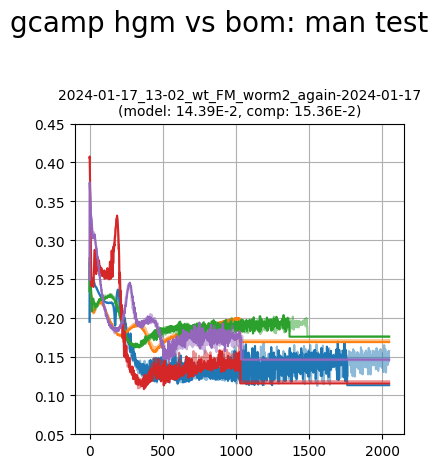

In [17]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: man test',
							  filenames_gcamp,
							  hgms_man_losses_gcamp, boms_man_losses_gcamp,
							  ylimits=None)

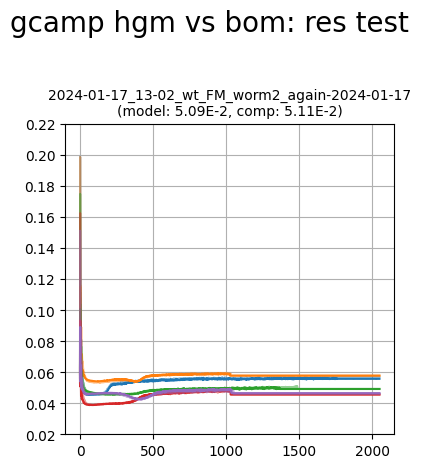

In [18]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: res test',
							  filenames_gcamp,
							  hgms_res_losses_gcamp, boms_res_losses_gcamp,
							  ylimits=None)

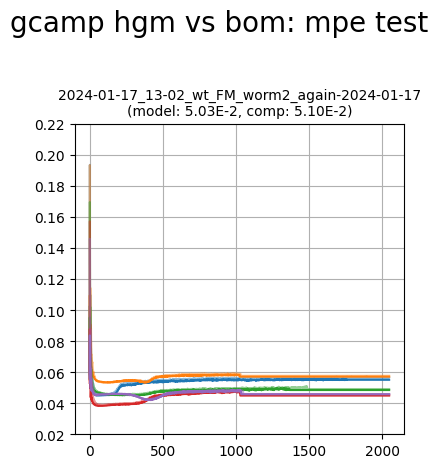

In [19]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe test',
							  filenames_gcamp,
							  hgms_mpe_losses_gcamp, boms_mpe_losses_gcamp,
							  ylimits=None)

## performance

In [20]:
neuron_scores_gcamp = assemble(boms_spn_gcamp, hgms_spn_gcamp)

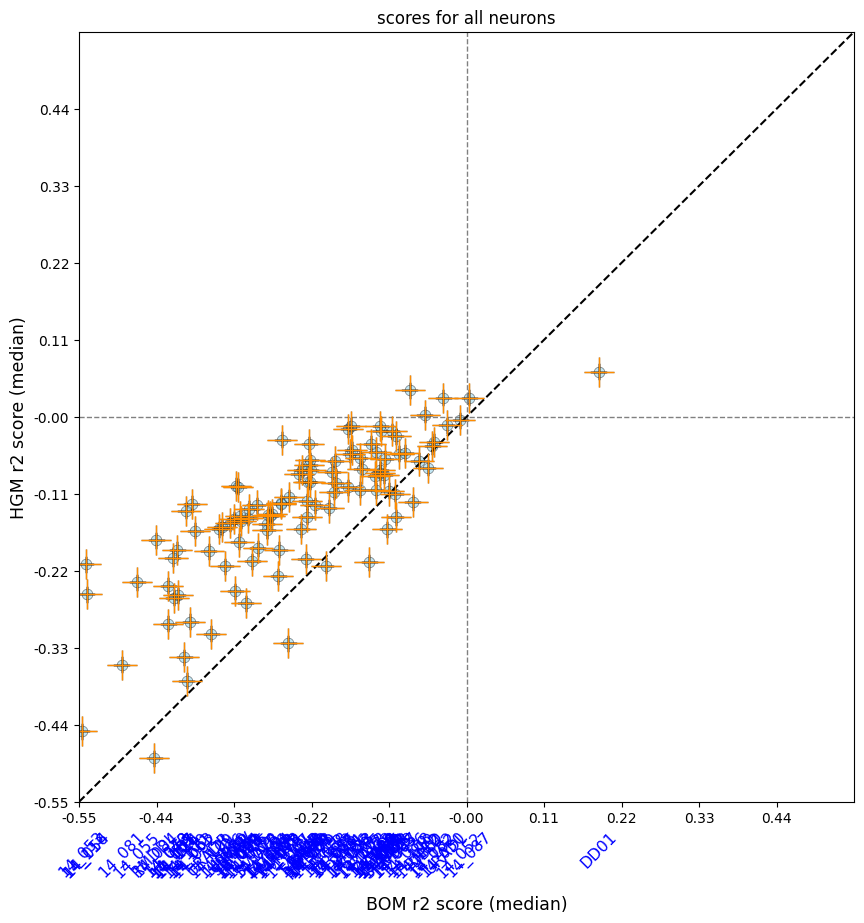

In [21]:
plot_utils.plot_performance_plot(neuron_scores_gcamp, None,
								 title='scores for all neurons', limits=(-0.55, 0.55, -0.55, 0.55))

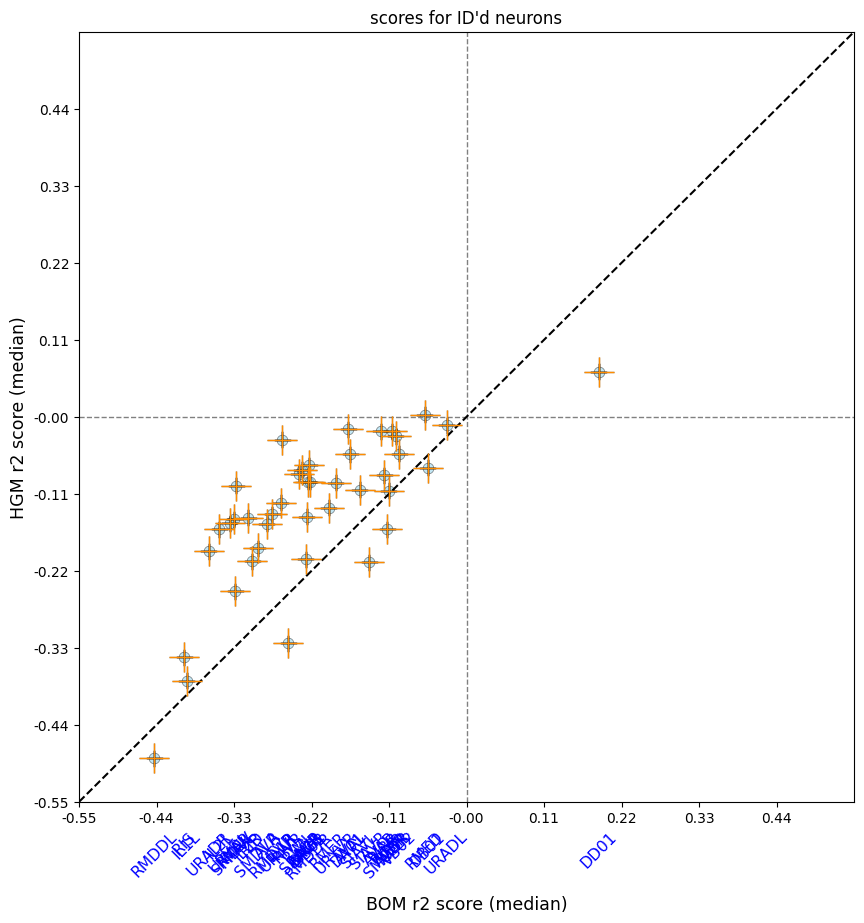

In [22]:
plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp if not key[0].isdigit()}, None,
								 title='scores for ID\'d neurons', limits=(-0.55, 0.55, -0.55, 0.55))

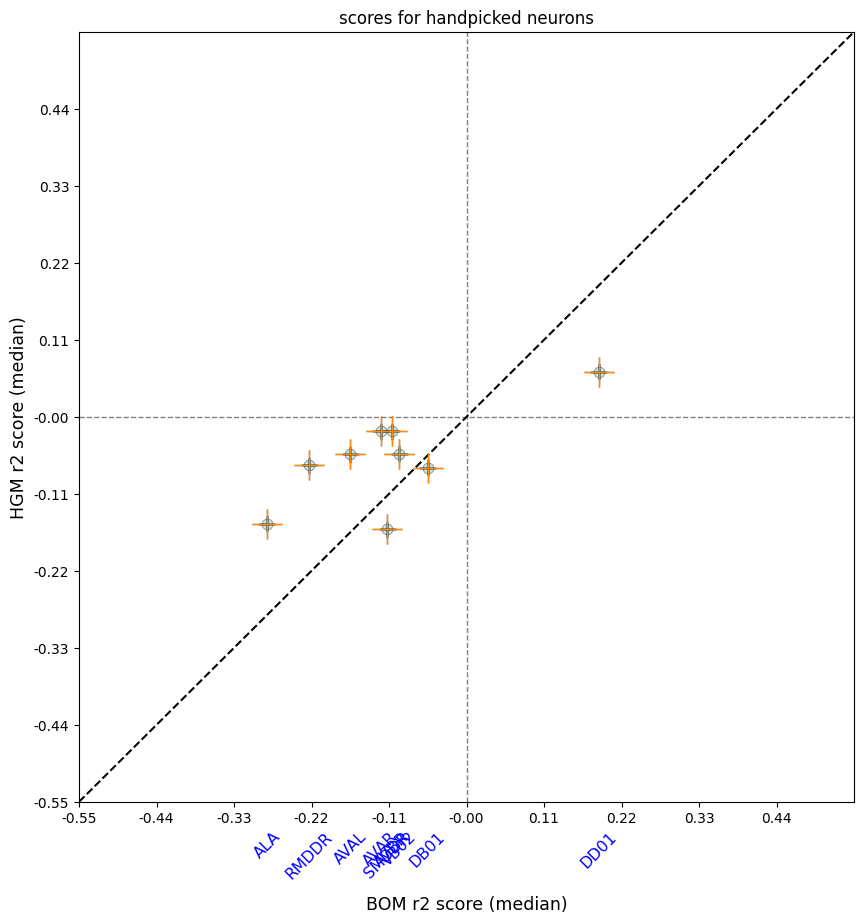

In [23]:
plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n_scores if key in neuron_scores_gcamp.keys()}, None,
								 title='scores for handpicked neurons', limits=(-0.55, 0.55, -0.55, 0.55))

## predict & score gfp

In [24]:
splits_gfp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gfp[i].shape[0]), discrete_states_gfp[i]['REV'].values)) for i in range(len(file_ids_gfp))]

In [25]:
boms_spn_man_rec_res_pres_gfp = [[
	bom.score_fn(params, traces_gfp[i].values[eval], eigenworms_gfp[i].values[eval]) for params, (train, eval) in zip(boms_params_gfp[i], splits_gfp[i])
] for i in range(len(file_ids_gfp))]

hgms_spn_man_rec_res_pres_gfp = [[
	hgm.score_fn(params, traces_gfp[i].values[eval], eigenworms_gfp[i].values[eval]) for params, (train, eval) in zip(hgms_params_gfp[i], splits_gfp[i])
] for i in range(len(file_ids_gfp))]

In [26]:
boms_spn_gfp = [
	[
		pd.DataFrame(data=np.array(split[0])[None], columns=traces_gfp[i].columns) for split in boms_spn_man_rec_res_pres_gfp[i]
	] for i in range(len(file_ids_gfp))
]

boms_man_gfp = [
	[
		pd.DataFrame(data=np.array(split[1]), columns=[f'M{i}' for i in range(dims)]) for split in boms_spn_man_rec_res_pres_gfp[i]
	] for i in range(len(file_ids_gfp))
]

(boms_rec_gfp,
 boms_res_gfp,
 boms_pres_gfp) = tuple(
	[
		[
			pd.DataFrame(data=np.array(split[m]), columns=traces_gfp[i].columns) for split in boms_spn_man_rec_res_pres_gfp[i]
		] for i in range(len(file_ids_gfp))
	] for m in [2, 3, 4]
)


hgms_spn_gfp = [
	[
		pd.DataFrame(data=np.array(split[0])[None], columns=traces_gfp[i].columns) for split in hgms_spn_man_rec_res_pres_gfp[i]
	] for i in range(len(file_ids_gfp))
]

hgms_man_gfp = [
	[
		pd.DataFrame(data=np.array(split[1]), columns=[f'M{i}' for i in range(dims)]) for split in hgms_spn_man_rec_res_pres_gfp[i]
	] for i in range(len(file_ids_gfp))
]

(hgms_rec_gfp,
 hgms_res_gfp,
 hgms_pres_gfp) = tuple(
	[
		[
			pd.DataFrame(data=np.array(split[m]), columns=traces_gfp[i].columns) for split in hgms_spn_man_rec_res_pres_gfp[i]
		] for i in range(len(file_ids_gfp))
	] for m in [2, 3, 4]
)

## performance

In [27]:
if gfp:
	neuron_scores_gfp = assemble(boms_spn_gfp, hgms_spn_gfp)

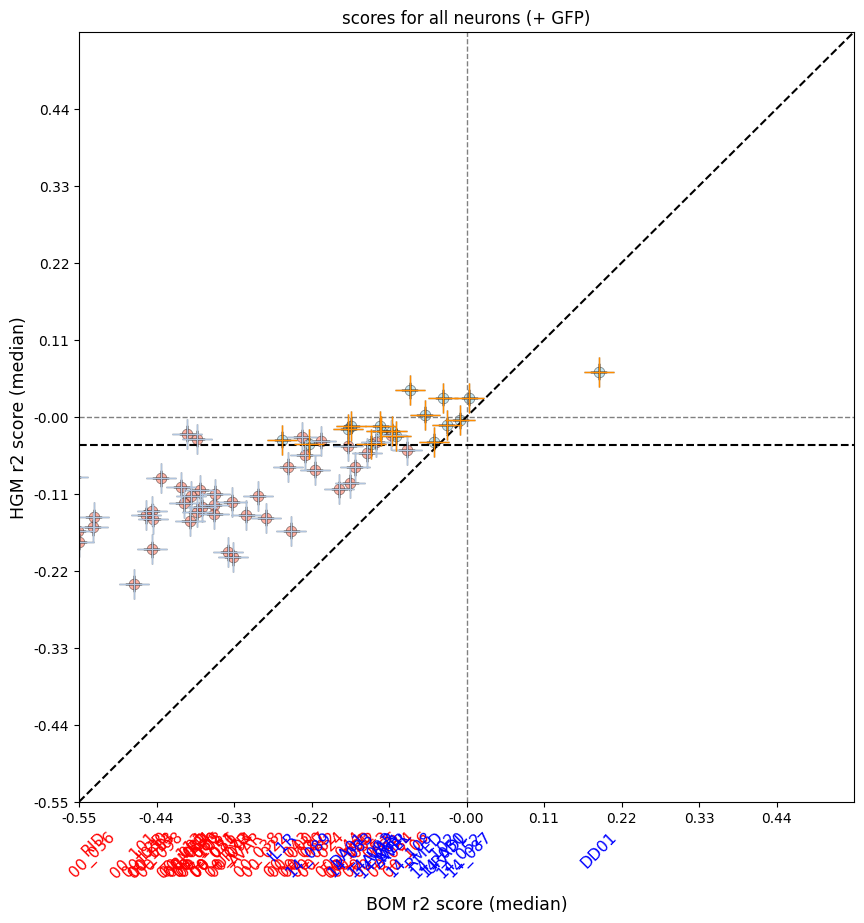

In [28]:
if gfp:
	plot_utils.plot_performance_plot(neuron_scores_gcamp, neuron_scores_gfp,
									 title='scores for all neurons (+ GFP)', limits=(-0.55, 0.55, -0.55, 0.55))

In [29]:
if gfp:
	high_score_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)

	neuron_scores_gcamp_signi = dict()
	for key in neuron_scores_gcamp.keys():
		scores_glm, scores_hgm = neuron_scores_gcamp[key]
		if len(scores_hgm.shape) == 0:
			scores_glm = scores_glm.reshape(1, 1)
			scores_hgm = scores_hgm.reshape(1, 1)

		y = np.median(scores_hgm)
		if y > high_score_hgm_gfp:
			neuron_scores_gcamp_signi[key] = (scores_glm, scores_hgm)

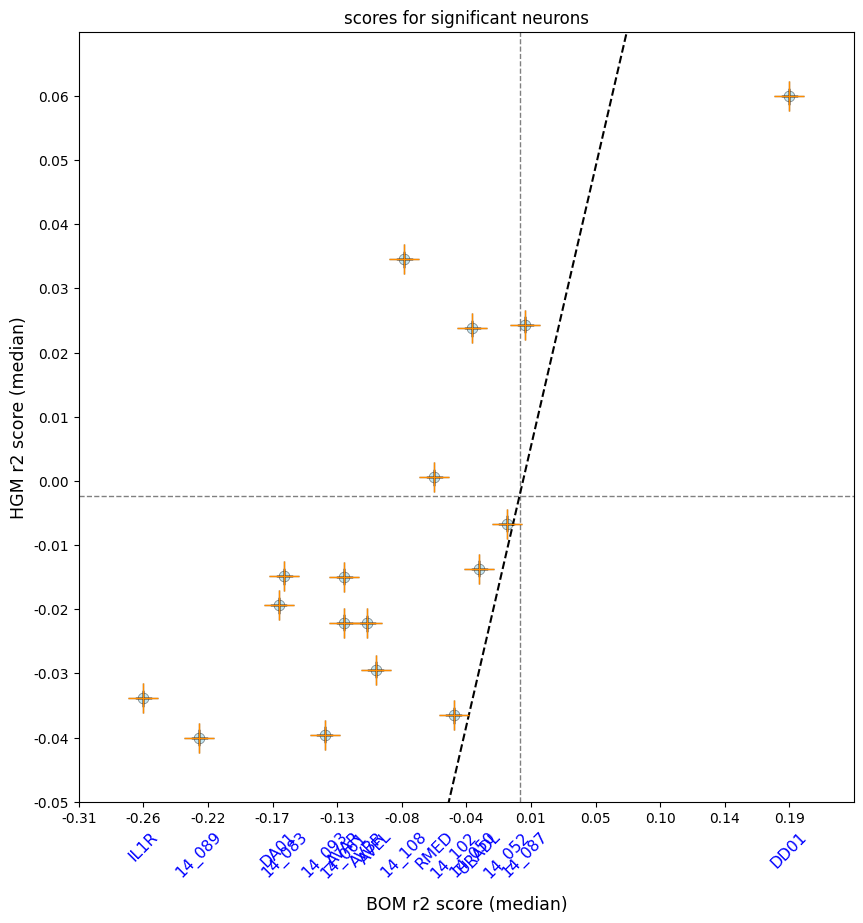

In [30]:
if gfp:
	plot_utils.plot_performance_plot(neuron_scores_gcamp_signi, None,
									 title='scores for significant neurons', limits=None)

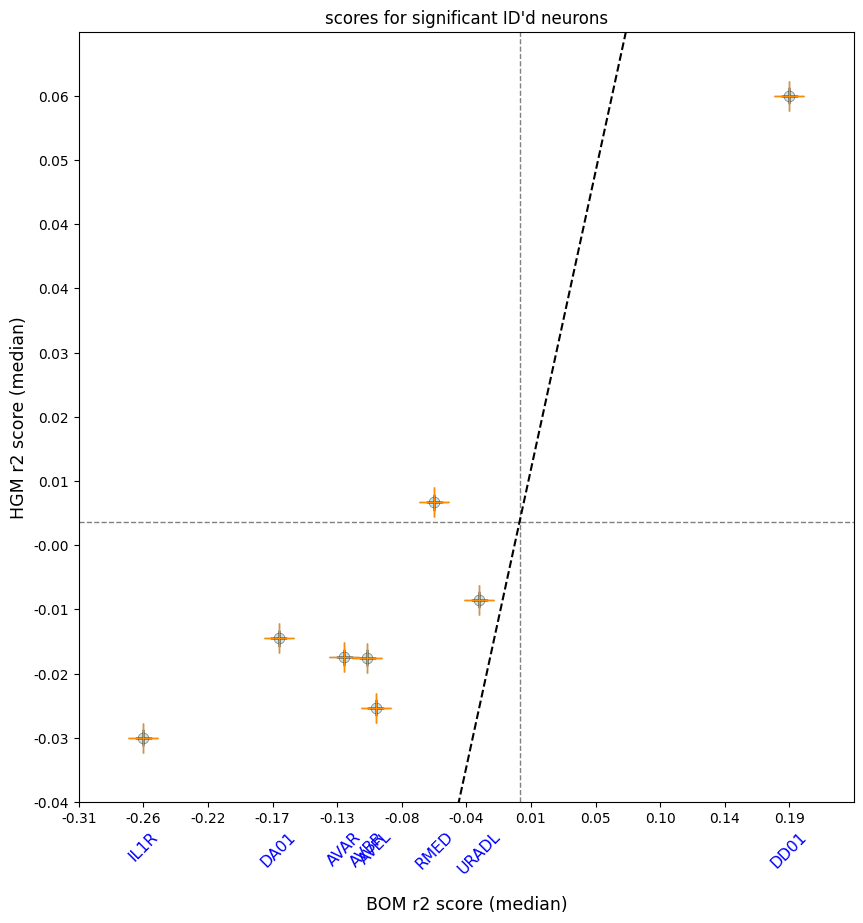

In [31]:
if gfp:
	plot_utils.plot_performance_plot({key: neuron_scores_gcamp_signi[key] for key in neuron_scores_gcamp_signi if not key[0].isdigit()}, None,
									 title='scores for significant ID\'d neurons', limits=None)

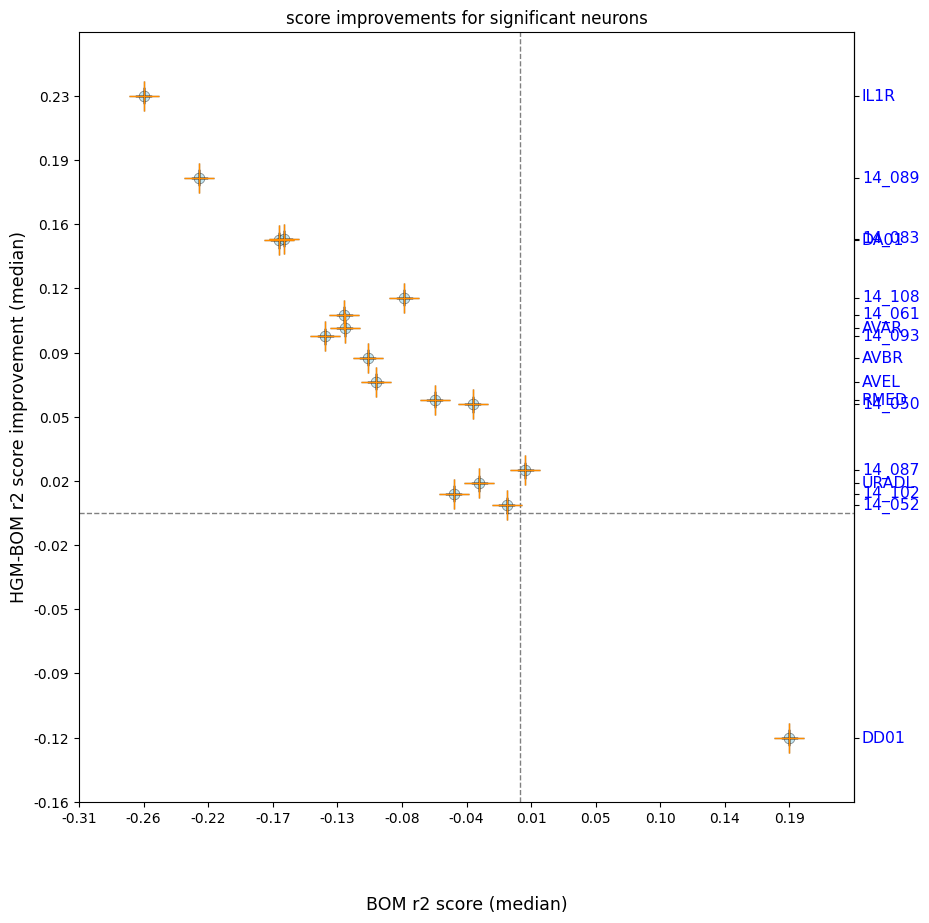

In [32]:
if gfp:
	plot_utils.plot_improvement_plot_y(neuron_scores_gcamp_signi, None,
									   title='score improvements for significant neurons', limits=None)

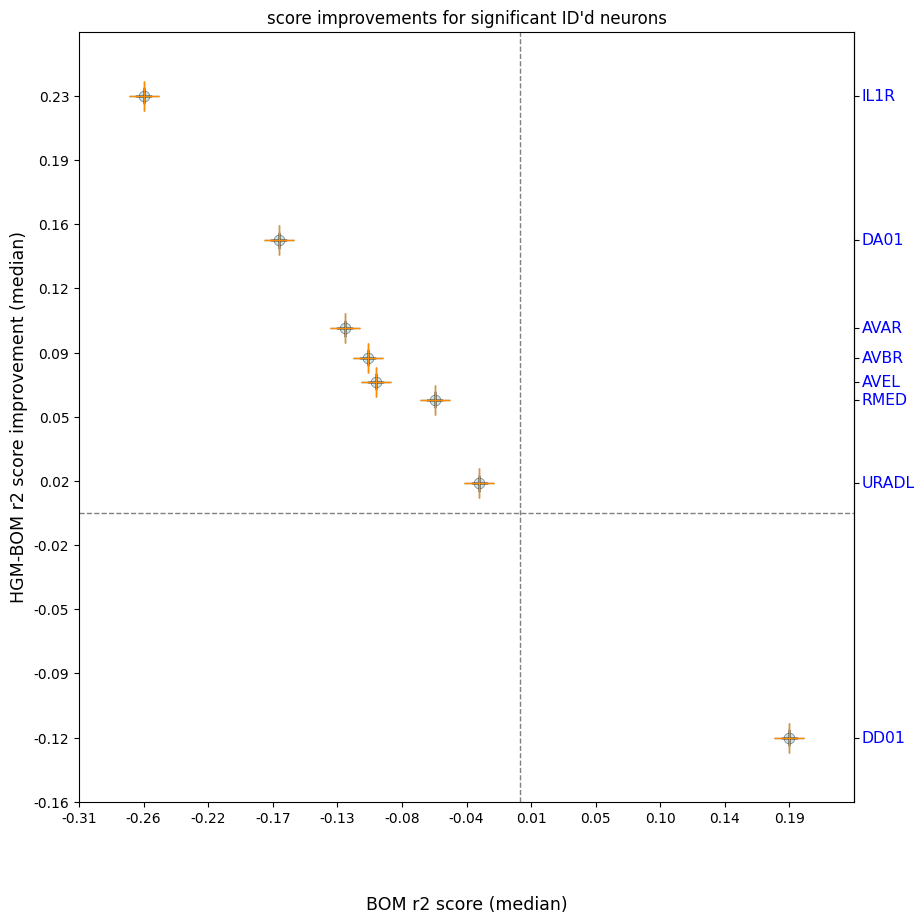

In [33]:
if gfp:
	plot_utils.plot_improvement_plot_y({key: neuron_scores_gcamp_signi[key] for key in neuron_scores_gcamp_signi.keys() if not key[0].isdigit()}, None,
									   title='score improvements for significant ID\'d neurons', limits=None)

## traces for IDd neurons

In [34]:
raise Exception

Exception: 

In [ ]:
neuron_signi_mean_impr = {key: np.mean(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in neuron_scores_gcamp_signi.keys()}
selection_n_signi_impr = [key for _, key in reversed(sorted(zip(neuron_signi_mean_impr.values(), neuron_signi_mean_impr.keys())))]

In [ ]:
selection_n_traces_ids_ = [label for label in selection_n_signi_impr if not label[0].isdigit()][:20]
selection_n_traces_ids = [n for n in selection_n_traces_ids_ if n in traces_gcamp[file_ids_gcamp.index(plot_id)].keys()]

In [ ]:
_, _, cca_rec_gcamp, _, _, _, _, _ = train_utils.get_manifolds(traces_gcamp, discrete_states_gcamp, n_cc=dims, n_pc=0)
cca_res_gcamp = [pd.DataFrame(data=trace_gcamp.values - cca_rec_gcamp_.values, columns=trace_gcamp.columns) for trace_gcamp, cca_rec_gcamp_ in zip(traces_gcamp, cca_rec_gcamp)]

In [ ]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions manifold',
	discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
	traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces_ids],
	[hgms_rec_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n_traces_ids] for i in range(splits)],
	[boms_rec_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n_traces_ids] for i in range(splits)],
	plot_first=True, plots_per_row=1, ylimits=None)

In [ ]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions residuals',
	discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
	traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces_ids],
	[hgms_res_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n_traces_ids] for i in range(splits)],
	[boms_res_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n_traces_ids] for i in range(splits)],
	plot_first=True, plots_per_row=1, ylimits=None)

In [ ]:
for i in range(5):
	plot_utils.plot_traces_comparisons(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} split {i} gcamp hgm & bom predictions residuals',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
		traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces_ids],
		[hgms_res_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n_traces_ids],
		 hgms_pres_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n_traces_ids]],
		[boms_res_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n_traces_ids],
		 boms_pres_gcamp[file_ids_gcamp.index(plot_id)][i][selection_n_traces_ids]],
		plot_first=False, plots_per_row=1, ylimits=None)

# traces for non IDd neurons

In [ ]:
raise Exception

In [ ]:
n_best = 20

In [ ]:
selection_n_traces_noids = [label for label in selection_n_signi_impr if label[0].isdigit()][:n_best]

In [ ]:
for label in selection_n_traces_noids:
	labels = [label]
	plot_id = int(label.split('_')[0])

	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions manifold',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
		traces_gcamp[file_ids_gcamp.index(plot_id)][labels],
		[hgms_rec_gcamp[file_ids_gcamp.index(plot_id)][i][labels] for i in range(splits)],
		[boms_rec_gcamp[file_ids_gcamp.index(plot_id)][i][labels] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=None,
		save_name=f'traces-no-id/{label}-manifolds')

	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions residuals',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
		traces_gcamp[file_ids_gcamp.index(plot_id)][labels],
		[hgms_res_gcamp[file_ids_gcamp.index(plot_id)][i][labels] for i in range(splits)],
		[boms_res_gcamp[file_ids_gcamp.index(plot_id)][i][labels] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=None,
		save_name=f'traces-no-id/{label}-residuals')

	for i in range(5):
		plot_utils.plot_traces_comparisons(
			f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} split {i} gcamp hgm & bom predictions residuals',
			discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
			traces_gcamp[file_ids_gcamp.index(plot_id)][labels],
			[hgms_res_gcamp[file_ids_gcamp.index(plot_id)][i][labels],
			 hgms_pres_gcamp[file_ids_gcamp.index(plot_id)][i][labels]],
			[boms_res_gcamp[file_ids_gcamp.index(plot_id)][i][labels],
			 boms_pres_gcamp[file_ids_gcamp.index(plot_id)][i][labels]],
			plot_first=False, plots_per_row=1, ylimits=None,
			save_name=f'traces-no-id/{label}-prediction-s{i}')

# Itamar

In [ ]:
raise Exception

In [ ]:
idd = False

selection_n_traces_chosen = sorted([label for label in neuron_scores_gcamp.keys() if label[0].isdigit() is not idd])

high_score_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)
high_score_bom_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)

neuron_scores_signficance = dict()
for key in selection_n_traces_chosen:
	scores_glm, scores_hgm = neuron_scores_gcamp[key]
	if len(scores_hgm.shape) == 0:
		scores_glm = scores_glm.reshape(1, 1)
		scores_hgm = scores_hgm.reshape(1, 1)

	neuron_scores_signficance[key] = (np.median(scores_glm) > high_score_hgm_gfp, np.median(scores_hgm) > high_score_hgm_gfp)

neuron_scores_median_impr = {key: np.median(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in selection_n_traces_chosen}

In [ ]:
data = [[key,
		 neuron_scores_gcamp[key][0][0][0],
		 neuron_scores_gcamp[key][1][0][0],
		 neuron_scores_signficance[key][0],
		 neuron_scores_signficance[key][1],
		 neuron_scores_median_impr[key]] for key in selection_n_traces_chosen]
if not idd:
	prepend = [filenames_gcamp[file_ids_gcamp.index(int(key.split('_')[0]))] for key in selection_n_traces_chosen]
	for e, p in zip(data, prepend): e.insert(0, p)

df = pd.DataFrame(data, columns=(['Worm'] if not idd else []) + ['Neuron', 'BOM_score', 'HGM_score', 'BOM_score_significant', 'HGM_score_significant', 'HGM-BOM_score_improvement'])
df.to_csv(f'./out/data/{'non' if not idd else ''}id_neurons.csv', index=False)